# code_223 · Inspection policy changes which outcomes become evidence

**Book:** section 42.3. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_42_GUIDE.md), [execution evidence](../CHAPTER_42_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_223).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Monitoring separates observable inputs, historical predictions, delayed outcome maturity, selection mechanisms, operational versions and authority to update. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8023;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8023


## A high-score inspection policy leaves part of the population unlabelled
 Fit a source logistic model on1,000 completely observed generated candidates. Create4,000 independent deployment candidates; the true finding law includes an unmodelled low-severity subgroup. A deterministic policy inspects p>=0.6. Only inspected outcomes enter the ordinary log. A second audit policy inspects high scores with probability1 and lower scores with probability0.15; the recorded propensity is known by design and selection uses an independent draw. Compute observed-only loss, full privileged simulator loss and the Horvitz–Thompson estimate sum(S loss/pi)/N. This finite estimate can be noisy and relies on known positive support; it does not repair arbitrary unmeasured selection or identify missing outcomes under the deterministic policy. No real inspections or consequential randomization are conducted.


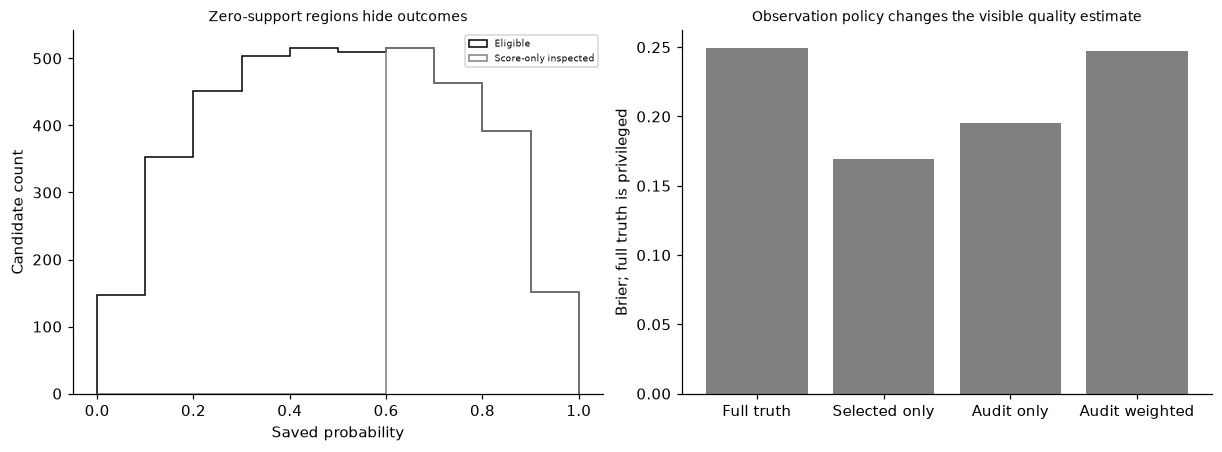

In [2]:
from sklearn.linear_model import LogisticRegression
xs=rng.normal(size=(1000,2));ys=rng.binomial(1,expit(1.3*xs[:,0]-.4*xs[:,1]));base=LogisticRegression(C=1).fit(xs,ys);xd=rng.normal(size=(4000,2));special=xd[:,0]<-.8;untreated=rng.binomial(1,expit(1.3*xd[:,0]-.4*xd[:,1]+2.5*special));p=base.predict_proba(xd)[:,1];selected=p>=.6;propensity=np.where(selected,1.,.15);audit=rng.random(4000)<propensity;loss=(p-untreated)**2;weighted=float(np.sum(loss[audit]/propensity[audit])/4000);assert np.all(propensity>0) and not np.any(selected&(p<.6));assert np.any(~selected&special);observed=np.where(audit,untreated,np.nan);assert np.all(np.isnan(observed[~audit]));RESULTS.update(source_complete_labels=1000,deployment_candidates=4000,deterministic_observed_labels=int(selected.sum()),deterministic_low_score_observation_probability=0.,audit_observed_labels=int(audit.sum()),audit_low_score_probability=.15,full_privileged_Brier=float(loss.mean()),deterministic_observed_only_Brier=float(loss[selected].mean()),audit_observed_only_Brier=float(loss[audit].mean()),audit_Horvitz_Thompson_Brier=weighted,unobserved_outcomes_are_zero=False,known_positive_propensity_assumption=True);fig,axes=plt.subplots(1,2,figsize=(11,4));bins=np.linspace(0,1,11);axes[0].hist(p,bins=bins,histtype='step',label='Eligible',color='black');axes[0].hist(p[selected],bins=bins,histtype='step',label='Score-only inspected',color='.5');axes[0].set(xlabel='Saved probability',ylabel='Candidate count',title='Zero-support regions hide outcomes');axes[0].legend(fontsize=6);axes[1].bar(['Full truth','Selected only','Audit only','Audit weighted'],[loss.mean(),loss[selected].mean(),loss[audit].mean(),weighted],color='.5');axes[1].set(ylabel='Brier; full truth is privileged',title='Observation policy changes the visible quality estimate');plt.show()


## Preserve the action and label definition before retraining
 Fit three updated models: observed high-score labels, positively supported audit labels with inverse-propensity weights, and an explicitly wrong control that fills all uninspected deterministic outcomes with zero. Assess2,000 independent fully labelled simulator candidates without selecting a model by those scores. A separate repair fixture prevents some generated untreated positives among inspected assets with probability0.7. Post-repair outcomes answer a different question from untreated finding risk; they are not substitute ground truth for the original event. Log the inspection action, repair action, observation mechanism and target version. The full untreated and repaired potential outcomes are simulator-only controls, not identified real-world counterfactuals. This laboratory does not implement the contraction method or establish convergence of repeated performative retraining.


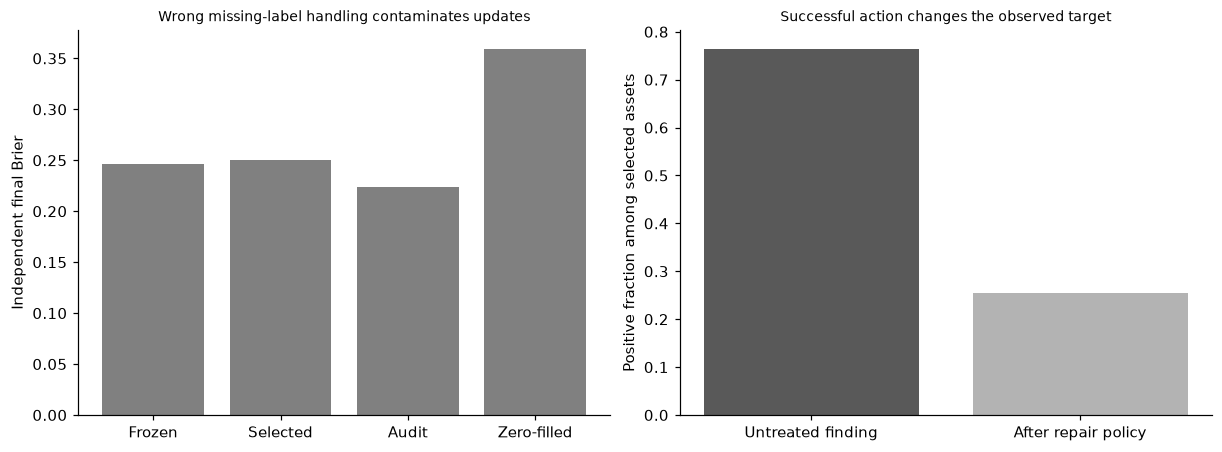

In [3]:
naive=LogisticRegression(C=1).fit(xd[selected],untreated[selected]);audit_model=LogisticRegression(C=1).fit(xd[audit],untreated[audit],sample_weight=1/propensity[audit]);wrong=LogisticRegression(C=1).fit(xd,np.where(selected,untreated,0));xf=rng.normal(size=(2000,2));yf=rng.binomial(1,expit(1.3*xf[:,0]-.4*xf[:,1]+2.5*(xf[:,0]<-.8)));models={'Frozen':base,'Selected update':naive,'Audit update':audit_model,'Zero-filled wrong':wrong};quality={name:float(np.mean((m.predict_proba(xf)[:,1]-yf)**2)) for name,m in models.items()};repair=selected&(rng.random(4000)<.7);post=untreated*(~repair);assert np.all(post<=untreated) and np.all(post[~repair]==untreated[~repair]);action_log=pd.DataFrame({'inspection':selected,'repair':repair,'label_observed':selected,'untreated_label_version':'finding-before-repair-v1','post_label_version':'outcome-after-policy-v2'});RESULTS.update(independent_final_candidates=2000,final_update_Brier=quality,repair_actions=int(repair.sum()),untreated_selected_positive_rate=float(untreated[selected].mean()),post_repair_selected_positive_rate=float(post[selected].mean()),action_and_label_versions_logged=True,full_potential_outcomes_are_privileged_simulator_controls=True,contraction_or_performative_convergence_implemented=False);assert len(action_log)==4000;fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(range(4),list(quality.values()),color='.5');axes[0].set(xticks=range(4),xticklabels=['Frozen','Selected','Audit','Zero-filled'],ylabel='Independent final Brier',title='Wrong missing-label handling contaminates updates');axes[1].bar(['Untreated finding','After repair policy'],[untreated[selected].mean(),post[selected].mean()],color=['.35','.7']);axes[1].set(ylabel='Positive fraction among selected assets',title='Successful action changes the observed target');plt.show()


In [4]:
summary={'example_id':'code_223','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual high-score selection with zero outcome support in low-score region', 'positive-probability audit sampling with known propensity weighted loss and independent assessment', 'observed selected retraining versus zero-filled-label contamination control', 'repair-induced outcomes separated from untreated potential outcomes and label-version changes'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual high-score selection with zero outcome support in low-score region", "positive-probability audit sampling with known propensity weighted loss and independent assessment", "observed selected retraining versus zero-filled-label contamination control", "repair-induced outcomes separated from untreated potential outcomes and label-version changes"], "elapsed_seconds": 0.366, "example_id": "code_223", "hardware": "Darwin arm64 CPU", "results": {"action_and_label_versions_logged": true, "audit_Horvitz_Thompson_Brier": 0.24697592278307665, "audit_low_score_probability": 0.15, "audit_observed_labels": 1884, "audit_observed_only_Brier": 0.19497719558312887, "contraction_or_performative_convergence_implemented": false, "deployment_candidates": 4000, "deterministic_low_score_observation_probability": 0.0, "deterministic_observed_labels": 1522, "deterministic_observed_only_Brier": 0.16939899730135952, "final_update_Brier": {"Audit update": 